# Dia 5 - Destaques: nomes de municipios + grafo de similaridade

Parte 1: trazer o nome de cada municipio (so tinhamos ibge6 ate agora) e
construir um grafo de similaridade entre municipios com base nas 3 features
de clustering (media_cobertura, variabilidade_cobertura, tendencia_cobertura),
pra usar como base da deteccao de outliers (Parte 2, z-score).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import json

pd.set_option("display.max_columns", None)

## Etapa A - nomes dos municipios

**Conceito:** em todas as etapas anteriores (Dia 3 e Dia 4) so trabalhamos com
`ibge6` (codigo IBGE de 6 digitos). Isso e otimo pra juntar tabelas, mas
pessimo pra contar uma historia -- ninguem reconhece "354570", mas reconhece
"Santa Albertina, SP". Pra qualquer grafico, ranking ou alerta que o usuario
final vai ler no Dia 6 (frontend), precisamos do nome.

A fonte e a API publica do IBGE
(`https://servicodados.ibge.gov.br/api/v1/localidades/municipios`), que devolve
um JSON com o nome de cada municipio e um codigo de **7 digitos** (6 digitos +
um digito verificador). Nosso dado usa 6 digitos, entao a hipotese e simples:
`ibge6 == codigo_7_digitos[:6]`. Isso so e seguro de usar se for **sempre**
verdade (sem ambiguidade) -- por isso o passo 2 confirma isso nos dados reais
antes de confiar na conversao, em vez de simplesmente assumir.

In [2]:
# Passo 1: buscar a lista de municipios na API do IBGE e carregar nossa
# tabela de clusters (Dia 4).
#
# A API comprime a resposta com gzip mesmo sem pedirmos -- por isso o
# gzip.decompress antes de interpretar como JSON.

import gzip
import urllib.request

url = "https://servicodados.ibge.gov.br/api/v1/localidades/municipios"
req = urllib.request.Request(url, headers={"Accept-Encoding": "identity"})
with urllib.request.urlopen(req, timeout=30) as resp:
    corpo = resp.read()
    if corpo[:2] == b"\x1f\x8b":
        corpo = gzip.decompress(corpo)
    municipios_api = json.loads(corpo.decode("utf-8"))

print(f"Municipios retornados pela API: {len(municipios_api)}")

clusters = pd.read_csv(
    "../data/processed/clusters_municipios_mvp.csv", dtype={"ibge6": str}
)
print(f"Nossa tabela de clusters: {clusters.shape}")
clusters.head()

Municipios retornados pela API: 5571
Nossa tabela de clusters: (5570, 9)


,ibge6,uf,media_cobertura,variabilidade_cobertura,tendencia_cobertura,cluster,isolamento_similaridade,nome_cluster,nome_municipio
0,110001,RO,85.479984,6.711533,-0.524181,0,0.078384,Cobertura alta e estavel,Alta Floresta D'Oeste
1,110002,RO,95.194050,5.817457,-1.433047,0,0.093926,Cobertura alta e estavel,Ariquemes
2,110003,RO,75.553063,16.091253,0.604157,1,0.161455,"Cobertura baixa, em recuperacao",Cabixi
3,110004,RO,94.814372,2.916858,-0.454656,0,0.104004,Cobertura alta e estavel,Cacoal
4,110005,RO,85.069178,6.920837,-0.794517,0,0.079144,Cobertura alta e estavel,Cerejeiras


In [3]:
# Passo 2: confirmar empiricamente que ibge6 == codigo_7_digitos[:6], sem
# ambiguidade, antes de usar essa regra pra qualquer coisa.
#
# Duas checagens:
#   (a) nenhum prefixo de 6 digitos pode aparecer em mais de um codigo de
#       7 digitos na API inteira (se aparecesse, nao saberiamos qual dos
#       dois e o nosso municipio);
#   (b) o nome que a conversao devolve pra alguns ibge6 conhecidos (capitais)
#       precisa fazer sentido.


def uf_do_municipio(item):
    # a maioria tem "microrregiao"; 1 municipio (Boa Esperanca do Norte, MT)
    # so tem "regiao-imediata" -- usamos como fallback.
    if item.get("microrregiao"):
        return item["microrregiao"]["mesorregiao"]["UF"]["sigla"]
    return item["regiao-imediata"]["regiao-intermediaria"]["UF"]["sigla"]


from collections import defaultdict

mapa_6_para_7 = defaultdict(list)
for item in municipios_api:
    codigo7 = str(item["id"])
    mapa_6_para_7[codigo7[:6]].append((codigo7, item["nome"], uf_do_municipio(item)))

ambiguos = {k: v for k, v in mapa_6_para_7.items() if len(v) > 1}
print(f"(a) prefixos de 6 digitos com mais de 1 codigo de 7 digitos: {len(ambiguos)}")

capitais_conhecidas = {
    "355030": "Sao Paulo",
    "330455": "Rio de Janeiro",
    "110020": "Porto Velho",
    "292740": "Salvador",
    "310620": "Belo Horizonte",
}
print("\n(b) spot-check com capitais conhecidas:")
for ibge6_teste, nome_esperado in capitais_conhecidas.items():
    nome_encontrado = mapa_6_para_7[ibge6_teste][0][1] if ibge6_teste in mapa_6_para_7 else None
    print(f"  {ibge6_teste} -> {nome_encontrado!r} (esperado: {nome_esperado!r})")

assert len(ambiguos) == 0, "Existe ambiguidade na conversao 6->7 digitos -- PARAR e investigar."
print("\nSem ambiguidade em nenhum dos", len(mapa_6_para_7), "codigos -- conversao confirmada, pode prosseguir.")

(a) prefixos de 6 digitos com mais de 1 codigo de 7 digitos: 0

(b) spot-check com capitais conhecidas:
  355030 -> 'São Paulo' (esperado: 'Sao Paulo')
  330455 -> 'Rio de Janeiro' (esperado: 'Rio de Janeiro')
  110020 -> 'Porto Velho' (esperado: 'Porto Velho')
  292740 -> 'Salvador' (esperado: 'Salvador')
  310620 -> 'Belo Horizonte' (esperado: 'Belo Horizonte')

Sem ambiguidade em nenhum dos 5571 codigos -- conversao confirmada, pode prosseguir.


In [4]:
# Passo 3: construir a tabela ibge6 -> nome_municipio e salvar em
# data/raw/municipios_nomes.csv (fonte pequena, pode ir pro Git).

nomes_municipios = pd.DataFrame(
    {
        "ibge6": [str(item["id"])[:6] for item in municipios_api],
        "nome_municipio": [item["nome"] for item in municipios_api],
    }
)

print("Duplicatas de ibge6 na tabela de nomes (deve ser 0):", nomes_municipios["ibge6"].duplicated().sum())

nomes_municipios.to_csv("../data/raw/municipios_nomes.csv", index=False, encoding="utf-8")
print(f"Salvo em data/raw/municipios_nomes.csv -- {len(nomes_municipios)} municipios")
nomes_municipios.head()

Duplicatas de ibge6 na tabela de nomes (deve ser 0): 0
Salvo em data/raw/municipios_nomes.csv -- 5571 municipios


,ibge6,nome_municipio
0,110001,Alta Floresta D'Oeste
1,110002,Ariquemes
2,110003,Cabixi
3,110004,Cacoal
4,110005,Cerejeiras


In [5]:
# Passo 4: juntar nome_municipio na tabela de clusters (left join, pra nao
# perder nenhuma linha mesmo que algum nome nao bata) e salvar de volta.
#
# drop(..., errors="ignore") antes do merge deixa a celula idempotente: se o
# notebook for reexecutado do zero, clusters_municipios_mvp.csv ja vai ter
# sido salvo com nome_municipio por uma execucao anterior, e sem o drop o
# merge geraria nome_municipio_x/nome_municipio_y em vez de sobrescrever.

n_linhas_antes = len(clusters)
clusters = clusters.drop(columns=["nome_municipio"], errors="ignore").merge(
    nomes_municipios, on="ibge6", how="left"
)

print(f"Linhas antes do merge: {n_linhas_antes} | depois: {len(clusters)}")
print("Nomes faltantes apos o merge:", clusters["nome_municipio"].isna().sum())

clusters.to_csv("../data/processed/clusters_municipios_mvp.csv", index=False)
clusters.head()

Linhas antes do merge: 5570 | depois: 5570
Nomes faltantes apos o merge: 0


,ibge6,uf,media_cobertura,variabilidade_cobertura,tendencia_cobertura,cluster,isolamento_similaridade,nome_cluster,nome_municipio
0,110001,RO,85.479984,6.711533,-0.524181,0,0.078384,Cobertura alta e estavel,Alta Floresta D'Oeste
1,110002,RO,95.194050,5.817457,-1.433047,0,0.093926,Cobertura alta e estavel,Ariquemes
2,110003,RO,75.553063,16.091253,0.604157,1,0.161455,"Cobertura baixa, em recuperacao",Cabixi
3,110004,RO,94.814372,2.916858,-0.454656,0,0.104004,Cobertura alta e estavel,Cacoal
4,110005,RO,85.069178,6.920837,-0.794517,0,0.079144,Cobertura alta e estavel,Cerejeiras


## Etapa B - grafo de similaridade

**Conceito:** cada municipio e um ponto no espaco das 3 features de
clustering (media, variabilidade, tendencia de cobertura). O KMeans do Dia 4
agrupou esses pontos em 3 "regioes" (clusters), mas dentro de cada regiao
alguns municipios ainda podem estar muito mais distantes dos seus vizinhos do
que a maioria -- esses sao candidatos a destaque/outlier mesmo sem sair do
seu cluster.

A ideia do grafo de k-vizinhos-mais-proximos (k-NN graph): ligar cada
municipio aos K=5 municipios mais parecidos com ele (menor distancia
euclidiana no espaco padronizado). Quem tem vizinhos "longe" em media --
mesmo sendo os 5 mais proximos que existem -- esta isolado no espaco de
features, o que e um sinal complementar (nao substitui) ao z-score temporal
que vamos calcular na Parte 2.

K=5 (decisao do escopo, nao recalculada aqui): pequeno o suficiente pra
capturar so vizinhanca local, grande o suficiente pra nao depender de um
unico vizinho acidental.

In [6]:
# Passo 5/6: padronizar as 3 features -- mesma formula do StandardScaler
# em numpy puro ja usada no Dia 4 (notebook02, Parte 2): (x - media) / desvio,
# ddof=0.

colunas_features = ["media_cobertura", "variabilidade_cobertura", "tendencia_cobertura"]
X = clusters[colunas_features].values

media_colunas = X.mean(axis=0)
desvio_colunas = X.std(axis=0, ddof=0)
X_padronizado = (X - media_colunas) / desvio_colunas

print("Media apos padronizacao (esperado ~0):", X_padronizado.mean(axis=0).round(4))
print("Desvio apos padronizacao (esperado ~1):", X_padronizado.std(axis=0).round(4))

Media apos padronizacao (esperado ~0): [0. 0. 0.]
Desvio apos padronizacao (esperado ~1): [1. 1. 1.]


In [7]:
# Passo 7: pra cada municipio, achar os K=5 vizinhos mais proximos (distancia
# euclidiana no espaco padronizado), processando em lotes de 500 pra nunca
# montar a matriz de distancia completa 5570x5570 de uma vez (seria ~250MB
# so pra essa matriz -- um lote de 500x5570 e ~25MB, bem mais leve).

K = 5
BATCH = 500
n = X_padronizado.shape[0]

vizinhos_idx = np.zeros((n, K), dtype=int)
vizinhos_dist = np.zeros((n, K), dtype=float)

for inicio in range(0, n, BATCH):
    fim = min(inicio + BATCH, n)
    bloco = X_padronizado[inicio:fim]  # (tamanho_lote, 3)

    # distancia euclidiana de cada ponto do lote pra TODOS os pontos
    diffs = bloco[:, None, :] - X_padronizado[None, :, :]  # (tamanho_lote, n, 3)
    dists = np.sqrt((diffs ** 2).sum(axis=2))  # (tamanho_lote, n)

    # excluir o proprio municipio (distancia 0 contra ele mesmo)
    for i_local, i_global in enumerate(range(inicio, fim)):
        dists[i_local, i_global] = np.inf

    idx_dos_5_mais_proximos = np.argsort(dists, axis=1)[:, :K]
    for i_local, i_global in enumerate(range(inicio, fim)):
        vizinhos_idx[i_global] = idx_dos_5_mais_proximos[i_local]
        vizinhos_dist[i_global] = dists[i_local, idx_dos_5_mais_proximos[i_local]]

print(f"Vizinhos calculados pros {n} municipios em lotes de {BATCH}.")
print("Exemplo (primeiro municipio):", clusters.loc[0, "ibge6"], clusters.loc[0, "nome_municipio"])
print("  5 vizinhos mais proximos:", clusters.loc[vizinhos_idx[0], "nome_municipio"].tolist())
print("  distancias:", vizinhos_dist[0].round(3))

Vizinhos calculados pros 5570 municipios em lotes de 500.
Exemplo (primeiro municipio): 110001 Alta Floresta D'Oeste
  5 vizinhos mais proximos: ['Seara', 'Pedreira', "Mirassol d'Oeste", 'Arraias', 'São Miguel do Oeste']
  distancias: [0.067 0.071 0.08  0.084 0.09 ]


In [8]:
# Passo 8: construir o grafo nao-direcionado com networkx (1 no por
# municipio, 1 aresta por vizinho k-NN, peso = distancia) e salvar a lista
# de arestas em CSV.

ibge6_array = clusters["ibge6"].values

arestas = pd.DataFrame(
    {
        "ibge6_origem": np.repeat(ibge6_array, K),
        "ibge6_destino": ibge6_array[vizinhos_idx.flatten()],
        "distancia": vizinhos_dist.flatten(),
    }
)
arestas.to_csv("../data/processed/grafo_similaridade_arestas.csv", index=False)

grafo = nx.Graph()
grafo.add_nodes_from(ibge6_array)
for _, linha in arestas.iterrows():
    grafo.add_edge(linha["ibge6_origem"], linha["ibge6_destino"], weight=linha["distancia"])

print(f"Arestas salvas: {arestas.shape[0]} linhas (= {n} municipios x K={K})")
print(f"Grafo: {grafo.number_of_nodes()} nos, {grafo.number_of_edges()} arestas unicas")
print("(arestas unicas < nos*K porque o vizinho A->B tambem conta quando B->A existe)")

Arestas salvas: 27850 linhas (= 5570 municipios x K=5)
Grafo: 5570 nos, 17320 arestas unicas
(arestas unicas < nos*K porque o vizinho A->B tambem conta quando B->A existe)


In [9]:
# Passo 9: score de isolamento = distancia media aos 5 vizinhos mais
# proximos. Quanto maior, mais isolado/atipico o municipio e no espaco de
# features (mesmo os vizinhos mais parecidos com ele estao longe).
#
# Tambem aproveitamos pra nomear os clusters (mesma logica do Dia 4,
# notebook02 Parte 4: le as estatisticas reais em vez de fixar o indice
# 0/1/2 na mao) -- facilita reportar os resultados em linguagem legivel.

clusters["isolamento_similaridade"] = vizinhos_dist.mean(axis=1)

estatisticas_cluster = clusters.groupby("cluster")[colunas_features].mean()
cluster_alta_estavel = estatisticas_cluster["media_cobertura"].idxmax()
demais = estatisticas_cluster.index.difference([cluster_alta_estavel])
cluster_recuperacao = estatisticas_cluster.loc[demais, "tendencia_cobertura"].idxmax()
cluster_queda = estatisticas_cluster.loc[demais, "tendencia_cobertura"].idxmin()

nomes_cluster = {
    cluster_alta_estavel: "Cobertura alta e estavel",
    cluster_recuperacao: "Cobertura baixa, em recuperacao",
    cluster_queda: "Cobertura em queda e instavel",
}
clusters["nome_cluster"] = clusters["cluster"].map(nomes_cluster)

clusters.to_csv("../data/processed/clusters_municipios_mvp.csv", index=False)

print("Coluna isolamento_similaridade adicionada e tabela salva.")
clusters["isolamento_similaridade"].describe()

Coluna isolamento_similaridade adicionada e tabela salva.


count    5570.000000
mean        0.169261
std         0.115644
min         0.049935
25%         0.103581
50%         0.135900
75%         0.194227
max         1.590957
Name: isolamento_similaridade, dtype: float64

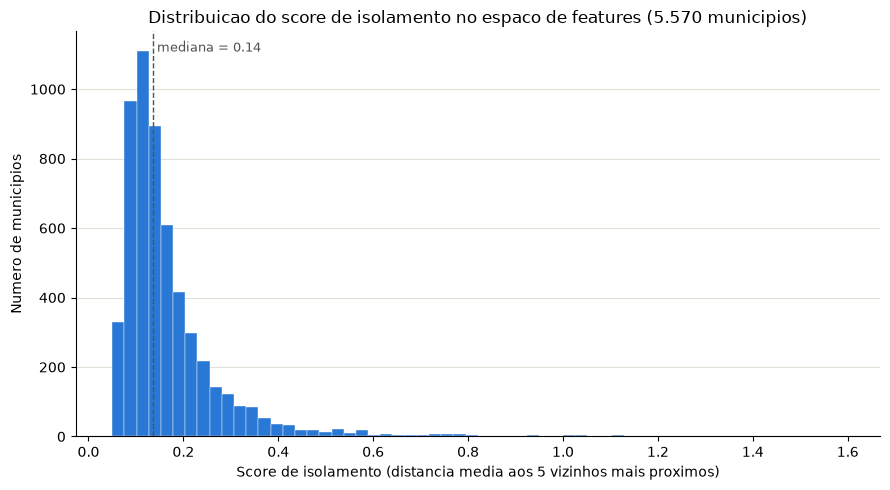

In [10]:
# Passo 10a: histograma da distribuicao do score de isolamento entre os
# 5.570 municipios.

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(clusters["isolamento_similaridade"], bins=60, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.3)
ax.set_xlabel("Score de isolamento (distancia media aos 5 vizinhos mais proximos)")
ax.set_ylabel("Numero de municipios")
ax.set_title("Distribuicao do score de isolamento no espaco de features (5.570 municipios)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

mediana = clusters["isolamento_similaridade"].median()
ax.axvline(mediana, color="#52514e", linestyle="--", linewidth=1)
ax.text(mediana, ax.get_ylim()[1] * 0.95, f" mediana = {mediana:.2f}", color="#52514e", fontsize=9)

plt.tight_layout()
plt.savefig("isolamento_similaridade_histograma.png", dpi=150)
plt.show()

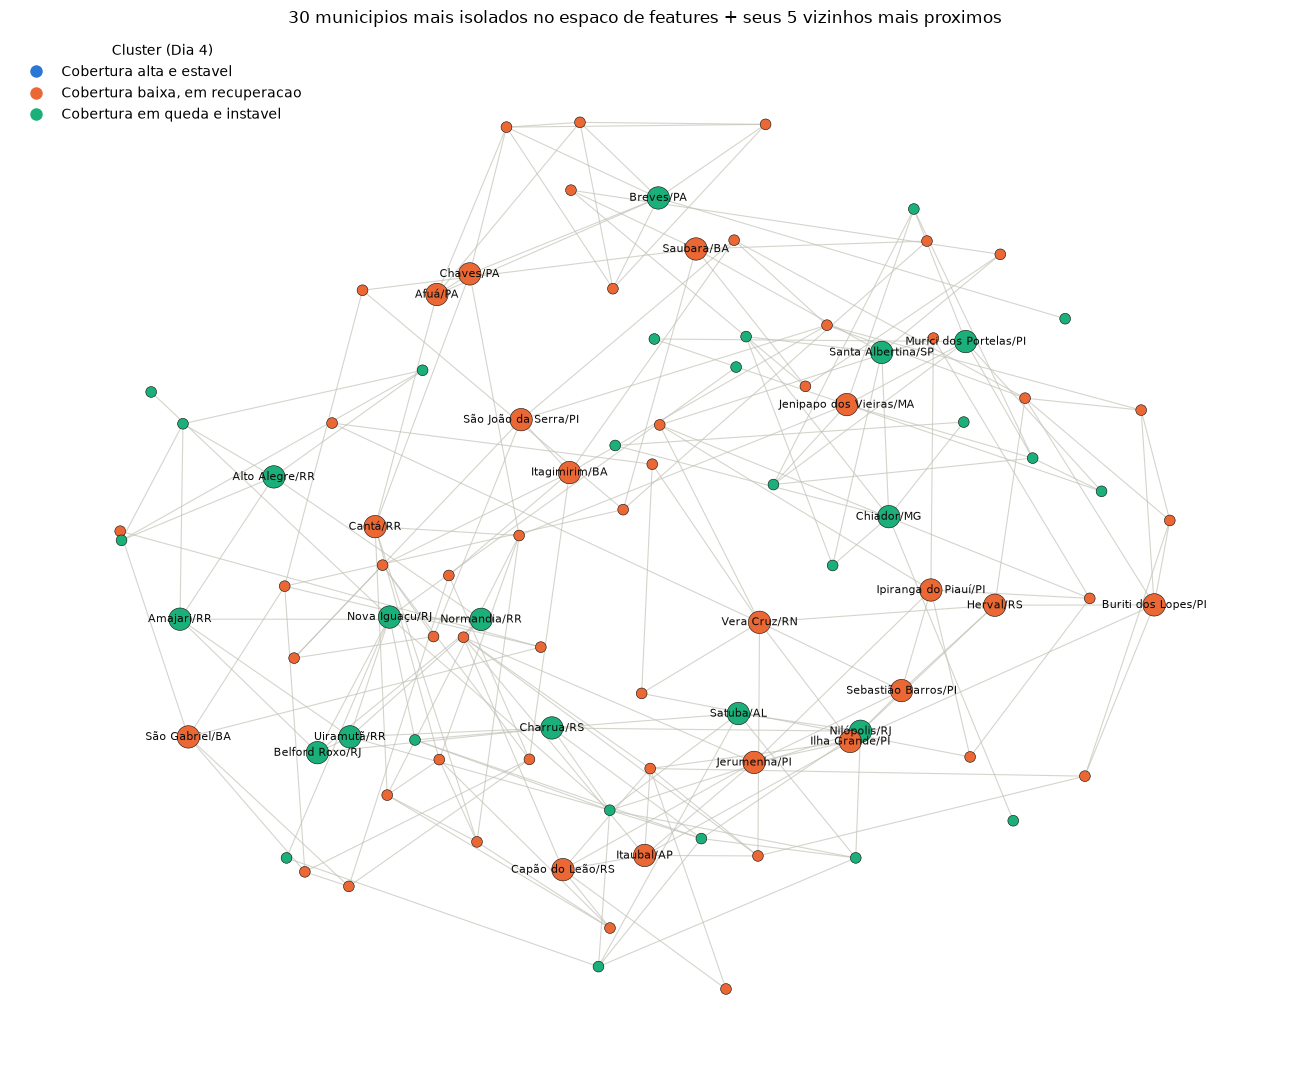

In [11]:
# Passo 10b: grafo visual so com os 30 municipios mais isolados + seus
# vizinhos diretos (o grafo inteiro com 5.570 nos seria ilegivel). Nos
# coloridos por cluster; rotulo de nome so nos 30 mais isolados (senao vira
# poluicao visual).

top30 = clusters.sort_values("isolamento_similaridade", ascending=False).head(30)
ibge6_top30 = set(top30["ibge6"])

ibge6_vizinhos_diretos = set()
for ibge6 in ibge6_top30:
    ibge6_vizinhos_diretos.update(grafo.neighbors(ibge6))

nos_do_subgrafo = ibge6_top30 | ibge6_vizinhos_diretos
subgrafo = grafo.subgraph(nos_do_subgrafo)

cor_por_cluster = {
    "Cobertura alta e estavel": "#2a78d6",      # slot 1 (azul) - paleta categorica
    "Cobertura baixa, em recuperacao": "#eb6834",  # slot 2 (laranja)
    "Cobertura em queda e instavel": "#1baf7a",    # slot 3 (aqua)
}
clusters_idx = clusters.set_index("ibge6")
nome_cluster_por_ibge6 = clusters_idx["nome_cluster"].to_dict()
nome_municipio_por_ibge6 = clusters_idx["nome_municipio"].to_dict()
uf_por_ibge6 = clusters_idx["uf"].to_dict()

cores_nos = [cor_por_cluster[nome_cluster_por_ibge6[ibge6]] for ibge6 in subgrafo.nodes()]
tamanhos_nos = [260 if ibge6 in ibge6_top30 else 60 for ibge6 in subgrafo.nodes()]

fig, ax = plt.subplots(figsize=(13, 11))
# seed/k escolhidos testando varias combinacoes e ficando com a que mais
# afasta os nos rotulados (top 30) entre si, pra minimizar rotulos colados.
pos = nx.spring_layout(subgrafo, seed=6, k=1.5, iterations=150)

nx.draw_networkx_edges(subgrafo, pos, ax=ax, edge_color="#c3c2b7", width=0.8, alpha=0.7)
nx.draw_networkx_nodes(
    subgrafo, pos, ax=ax, node_color=cores_nos, node_size=tamanhos_nos,
    edgecolors="#0b0b0b", linewidths=0.4,
)

rotulos_top30 = {
    ibge6: f"{nome_municipio_por_ibge6[ibge6]}/{uf_por_ibge6[ibge6]}"
    for ibge6 in ibge6_top30
}
nx.draw_networkx_labels(subgrafo, pos, labels=rotulos_top30, ax=ax, font_size=8, font_color="#0b0b0b")

handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=10, label=nome)
           for nome, c in cor_por_cluster.items()]
ax.legend(handles=handles, loc="upper left", frameon=False, title="Cluster (Dia 4)")
ax.set_title("30 municipios mais isolados no espaco de features + seus 5 vizinhos mais proximos")
ax.axis("off")

plt.tight_layout()
plt.savefig("grafo_similaridade_top30_isolados.png", dpi=150)
plt.show()

In [12]:
# Passo 11: resumo final -- top 10 municipios mais isolados e como os 30
# mais isolados se distribuem entre os 3 clusters do Dia 4.

print("=== TOP 10 MUNICIPIOS MAIS ISOLADOS (espaco de features) ===\n")
print(
    top30.head(10)[["ibge6", "nome_municipio", "uf", "nome_cluster", "isolamento_similaridade"]]
    .rename(columns={"isolamento_similaridade": "isolamento"})
    .to_string(index=False)
)

print("\n=== DISTRIBUICAO DOS 30 MAIS ISOLADOS ENTRE OS CLUSTERS ===\n")
print(top30["nome_cluster"].value_counts())

=== TOP 10 MUNICIPIOS MAIS ISOLADOS (espaco de features) ===

 ibge6    nome_municipio uf                    nome_cluster  isolamento
354570   Santa Albertina SP   Cobertura em queda e instavel    1.590957
430710            Herval RS Cobertura baixa, em recuperacao    1.355578
221062  Sebastião Barros PI Cobertura baixa, em recuperacao    1.221408
330320         Nilópolis RJ   Cobertura em queda e instavel    1.116582
150250            Chaves PA Cobertura baixa, em recuperacao    1.114826
140002           Amajari RR   Cobertura em queda e instavel    1.104084
270890            Satuba AL   Cobertura em queda e instavel    1.088037
140005       Alto Alegre RR   Cobertura em queda e instavel    1.079709
220465       Ilha Grande PI Cobertura baixa, em recuperacao    1.056563
220990 São João da Serra PI Cobertura baixa, em recuperacao    1.055191

=== DISTRIBUICAO DOS 30 MAIS ISOLADOS ENTRE OS CLUSTERS ===

nome_cluster
Cobertura baixa, em recuperacao    17
Cobertura em queda e instavel    

# Dia 5 - Parte 2: detecao de queda atipica por z-score

**Conceito:** o grafo de similaridade (Parte 1) compara municipios entre si no
espaco de features agregadas (media/variabilidade/tendencia dos 10 anos
inteiros) -- bom pra achar "perfil atipico", mas nao aponta EM QUE ANO algo
deu errado. Aqui a pergunta e diferente: olhando ano a ano, algum municipio
caiu muito mais que o normal NAQUELE ano especifico?

**Decisao de design (a parte importante):** "queda atipica" e definida
**por ano**, comparando cada municipio com todos os outros naquele MESMO
ano -- nao com o proprio historico dele. Por que: 2020-2022 tiveram uma
queda nacional de cobertura vacinal (pandemia) que atingiu quase todo mundo.
Se comparassemos cada municipio com o proprio passado, o z-score ia marcar
metade do Brasil como "queda atipica" em 2021 -- isso so capturaria o
choque nacional, nao um problema especifico do municipio. Calculando a
media e o desvio padrao do delta DENTRO de cada ano, o choque nacional vira
parte da "normalidade esperada" daquele ano, e so sobra como destaque quem
caiu muito mais que os pares no mesmo contexto.

**Escopo (decisao tomada agora):** o grafo de similaridade do Dia 5 Parte 1
fica, por enquanto, so como grafico + score de isolamento (contexto visual
e uma feature a mais pra interpretar os destaques). Deteccao de comunidade
no grafo e qualquer previsao baseada nele ficam fora do escopo dos 5 dias --
possivel iteracao futura do projeto.

In [13]:
# Passo 1: cobertura geral do municipio por ano -- mesma logica do Dia 4
# Parte 1 (notebook02, Passo 2): media de cobertura_capada entre as 5
# vacinas, por (ibge6, ano), ignorando NaN.

serie = pd.read_csv(
    "../data/processed/serie_temporal_mvp.csv",
    dtype={"ibge6": str, "uf": str, "imunizante": str},
)
print(f"Linhas da serie temporal: {len(serie)}")

cobertura_geral = serie.groupby(["ibge6", "ano"])["cobertura_capada"].mean().reset_index()
print(f"cobertura_geral shape: {cobertura_geral.shape}")
print(f"Nulos (nenhuma das 5 vacinas tinha dado naquele ibge6/ano): {cobertura_geral['cobertura_capada'].isna().sum()}")
cobertura_geral.head()

Linhas da serie temporal: 278500
cobertura_geral shape: (55700, 3)
Nulos (nenhuma das 5 vacinas tinha dado naquele ibge6/ano): 16


,ibge6,ano,cobertura_capada
0,110001,2014,92.78594
1,110001,2015,79.14210
2,110001,2016,79.60246
3,110001,2017,88.87006
4,110001,2018,91.24544


In [14]:
# Passo 2: delta ano a ano da cobertura geral de cada municipio.
#
# delta(ano) = valor(ano) - valor(ano-1), SO quando:
#   (a) ano e ano-1 sao anos consecutivos (shift dentro do grupo ibge6, que
#       ja esta ordenado por ano -- se faltasse um ano no meio, o shift
#       pegaria um ano nao-consecutivo, por isso o teste explicito abaixo);
#   (b) os dois valores existem (sem interpolar os ~16 buracos).

cobertura_geral = cobertura_geral.sort_values(["ibge6", "ano"]).reset_index(drop=True)
cobertura_geral["valor_ano_anterior"] = cobertura_geral.groupby("ibge6")["cobertura_capada"].shift(1)
cobertura_geral["ano_anterior"] = cobertura_geral.groupby("ibge6")["ano"].shift(1)

eh_consecutivo = (cobertura_geral["ano"] - cobertura_geral["ano_anterior"]) == 1
ambos_validos = cobertura_geral["cobertura_capada"].notna() & cobertura_geral["valor_ano_anterior"].notna()
delta_valido = eh_consecutivo & ambos_validos

cobertura_geral["delta"] = np.nan
cobertura_geral.loc[delta_valido, "delta"] = (
    cobertura_geral.loc[delta_valido, "cobertura_capada"] - cobertura_geral.loc[delta_valido, "valor_ano_anterior"]
)

deltas = cobertura_geral.dropna(subset=["delta"]).copy()
print(f"Deltas validos calculados: {len(deltas)}")
print("Anos presentes:", sorted(deltas['ano'].unique()))
print("\nContagem de delta valido por ano (maximo possivel: 5.570 municipios):")
print(deltas["ano"].value_counts().sort_index())

Deltas validos calculados: 50103
Anos presentes: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

Contagem de delta valido por ano (maximo possivel: 5.570 municipios):
ano
2015    5564
2016    5563
2017    5567
2018    5570
2019    5568
2020    5567
2021    5567
2022    5568
2023    5569
Name: count, dtype: int64


In [15]:
# Passo 3/4: media e desvio padrao do delta por ano (distribuicao nacional
# de "quanto a cobertura mudou nesse ano"), e z-score de cada (municipio,
# ano). ddof=0 pra manter consistencia com o StandardScaler do Dia 4 --
# tratamos os municipios com delta valido como a populacao inteira daquele
# ano, nao uma amostra dela.

estatisticas_ano = (
    deltas.groupby("ano")["delta"]
    .agg(media_nacional="mean", desvio_nacional=lambda s: s.std(ddof=0))
    .reset_index()
)
print("Estatisticas do delta por ano (media e desvio padrao nacional):")
print(estatisticas_ano.to_string(index=False))

deltas = deltas.merge(estatisticas_ano, on="ano")
deltas["z_score"] = (deltas["delta"] - deltas["media_nacional"]) / deltas["desvio_nacional"]

Estatisticas do delta por ano (media e desvio padrao nacional):
 ano  media_nacional  desvio_nacional
2015       -1.231546        13.380267
2016       -3.990096        16.728149
2017        2.480087        16.009370
2018       -0.658168        12.258746
2019       -3.323695        12.231634
2020       -4.604408        16.613975
2021       -3.264962        15.901579
2022       10.594138        16.437456
2023        7.674959        14.640699


In [16]:
# Passo 5/6: marcar "queda atipica" (z < -2, convencao estatistica comum de
# 2 desvios-padrao abaixo da media) e montar a tabela final: ibge6,
# nome_municipio, uf, ano, delta, z_score, cluster. Ordenada do mais
# negativo pro menos negativo. Salva em data/processed/destaques_quedas_atipicas.csv.

quedas_atipicas = deltas[deltas["z_score"] < -2].copy()
print(f"Casos marcados como queda atipica (z < -2): {len(quedas_atipicas)}")

quedas_atipicas = quedas_atipicas.merge(
    clusters[["ibge6", "nome_municipio", "uf", "cluster"]], on="ibge6", how="left"
)
print("Nomes/UF/cluster faltantes apos o merge:", quedas_atipicas[["nome_municipio", "uf", "cluster"]].isna().any(axis=1).sum())

destaques_quedas = (
    quedas_atipicas[["ibge6", "nome_municipio", "uf", "ano", "delta", "z_score", "cluster"]]
    .sort_values("z_score")
    .reset_index(drop=True)
)
destaques_quedas.to_csv("../data/processed/destaques_quedas_atipicas.csv", index=False)

print(f"\nSalvo em data/processed/destaques_quedas_atipicas.csv -- {destaques_quedas.shape}")
destaques_quedas.head()

Casos marcados como queda atipica (z < -2): 1492
Nomes/UF/cluster faltantes apos o merge: 0

Salvo em data/processed/destaques_quedas_atipicas.csv -- (1492, 7)


,ibge6,nome_municipio,uf,ano,delta,z_score,cluster
0,430200,Barros Cassal,RS,2015,-95.229360,-7.025108,1
1,421189,Painel,SC,2018,-82.634256,-6.687151,1
2,354075,Potim,SP,2019,-72.593720,-5.663187,1
3,290410,Boquira,BA,2015,-76.768888,-5.645429,1
4,230610,Irauçuba,CE,2019,-71.309080,-5.558160,2


In [17]:
# Passo 7: validacao -- distribuicao por ano e teste da hipotese central
# (z-score por ano deveria IMPEDIR que os anos de pandemia dominem os
# destaques, porque a queda nacional vira parte da "normalidade" daquele
# ano em vez de sobrar como destaque).

print(f"Total de destaques: {len(destaques_quedas)}\n")

print("Distribuicao por ano:")
print(destaques_quedas["ano"].value_counts().sort_index())

anos_pandemia = {2020, 2021, 2022}
n_pandemia = destaques_quedas["ano"].isin(anos_pandemia).sum()
n_total = len(destaques_quedas)
n_anos_com_delta = destaques_quedas["ano"].nunique()
esperado_uniforme_pct = 3 / n_anos_com_delta * 100

print(f"\nCasos em anos de pandemia (2020-2022): {n_pandemia} de {n_total} ({n_pandemia / n_total * 100:.1f}%)")
print(f"Esperado se os destaques se distribuissem uniformemente entre os {n_anos_com_delta} anos com delta valido: {esperado_uniforme_pct:.1f}%")
print(
    "-> os anos de pandemia NAO estao sobre-representados"
    if n_pandemia / n_total * 100 <= esperado_uniforme_pct + 3
    else "-> ATENCAO: anos de pandemia estao sobre-representados, revisar a logica do z-score por ano"
)

print("\n15 casos mais extremos (maior queda em z-score):")
print(destaques_quedas.head(15).to_string(index=False))

Total de destaques: 1492

Distribuicao por ano:
ano
2015    176
2016    239
2017    101
2018    172
2019    165
2020    194
2021    180
2022    112
2023    153
Name: count, dtype: int64

Casos em anos de pandemia (2020-2022): 486 de 1492 (32.6%)
Esperado se os destaques se distribuissem uniformemente entre os 9 anos com delta valido: 33.3%
-> os anos de pandemia NAO estao sobre-representados

15 casos mais extremos (maior queda em z-score):
 ibge6        nome_municipio uf  ano      delta   z_score  cluster
430200         Barros Cassal RS 2015 -95.229360 -7.025108        1
421189                Painel SC 2018 -82.634256 -6.687151        1
354075                 Potim SP 2019 -72.593720 -5.663187        1
290410               Boquira BA 2015 -76.768888 -5.645429        1
230610              Irauçuba CE 2019 -71.309080 -5.558160        2
354570       Santa Albertina SP 2016 -96.040730 -5.502739        2
312040       Cristiano Otoni MG 2015 -74.380680 -5.466941        2
293040           Se